# Week 4 — Open-Source Image Generation and Image Captioning

## 1. Objective
This notebook builds and evaluates an image generation and captioning workflow with open-source models. Stable Diffusion generates product imagery from text prompts under controlled changes to prompt and settings. A vision-language model then describes the images, and both the images and the captions are evaluated.

## 2. Theme and Task
The theme continues the portfolio's sustainable product, **TerraFlask**: a matte sage-green, recycled stainless steel water bottle with a bamboo lid, marketed to university students in hot-climate cities.

Week 1 found two clear failures when Stable Diffusion v1.5 generated this product:
1. **The bamboo lid appeared in none of six images.** Lids came out as steel, black or green.
2. **Every scene defaulted to a temperate, green, European-style park**, despite a "hot sunny" campus prompt.

This notebook asks whether those failures can be fixed with prompt design, generation settings and structural conditioning (ControlNet). It then tests whether an open-source captioning model can describe the results accurately enough to serve as **automatic alt text** for product images. Alt text makes a shop accessible to screen-reader users, linking the work to **SDG 10 (Reduced Inequalities)** alongside SDG 12.

## 3. Workflow

| Stage | Model | Purpose |
|---|---|---|
| Image generation | `stable-diffusion-v1-5/stable-diffusion-v1-5` (CreativeML OpenRAIL-M) | Text-to-image at 512×512, float16 |
| Structural control | `lllyasviel/sd-controlnet-canny` | Fixes the bottle and lid shape from an edge map |
| Captioning and VQA | `Salesforce/blip2-opt-2.7b` (MIT licence) | Captions and answers questions about each image |
| Alignment scoring | `openai/clip-vit-base-patch32` (MIT licence) | Image–text similarity and zero-shot attribute checks |

Experiments run in four groups, each changing one factor at a time with a fixed seed so differences can be attributed:
- **A.** A prompt-and-settings ladder (Lab Exercise 1)
- **B.** Seed consistency
- **C.** Scheduler comparison
- **D.** ControlNet conditioning

## 4. Environment Setup

In [1]:
!pip install -q -U diffusers accelerate

import os, gc, time, json, platform, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import cv2
import torch, transformers, diffusers
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from diffusers import (StableDiffusionPipeline, StableDiffusionControlNetPipeline, ControlNetModel,
                       PNDMScheduler, DPMSolverMultistepScheduler, EulerAncestralDiscreteScheduler, DDIMScheduler)

os.makedirs("outputs", exist_ok=True)
pd.set_option("display.max_colwidth", 120)
print("Python:", platform.python_version(), "| PyTorch:", torch.__version__,
      "| transformers:", transformers.__version__, "| diffusers:", diffusers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

Python: 3.13.16 | PyTorch: 2.14.1+cu130 | transformers: 5.22.1 | diffusers: 0.42.1
GPU: Tesla T4


## 5. Image Generation Setup
Every image is generated through one function that records its prompt, negative prompt, guidance scale, steps, seed, scheduler and generation time, so each image can be reproduced exactly. All images are saved to `outputs/`.

In [2]:
pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5", torch_dtype=torch.float16).to("cuda")
pipe.set_progress_bar_config(disable=True)
DEFAULT_SCHEDULER_CONFIG = pipe.scheduler.config
SCHEDULERS = {
    "PNDM": PNDMScheduler,
    "DPM-Solver++": DPMSolverMultistepScheduler,
    "Euler Ancestral": EulerAncestralDiscreteScheduler,
    "DDIM": DDIMScheduler,
}

records = []

def generate(label, prompt, negative="", cfg=7.5, steps=30, seed=42, scheduler="PNDM",
             group="", pipeline=None, control_image=None, control_scale=None):
    p = pipeline or pipe
    p.scheduler = SCHEDULERS[scheduler].from_config(DEFAULT_SCHEDULER_CONFIG)
    generator = torch.Generator("cuda").manual_seed(seed)
    kwargs = dict(prompt=prompt, negative_prompt=negative or None, guidance_scale=cfg,
                  num_inference_steps=steps, generator=generator)
    if control_image is not None:
        kwargs.update(image=control_image, controlnet_conditioning_scale=control_scale)
    start = time.time()
    image = p(**kwargs).images[0]
    seconds = round(time.time() - start, 1)
    file = f"outputs/{label}.png"
    image.save(file)
    rec = dict(label=label, group=group, prompt=prompt, negative_prompt=negative, guidance_scale=cfg,
               steps=steps, seed=seed, scheduler=scheduler, controlnet_scale=control_scale,
               seconds=seconds, file=file, image=image)
    records.append(rec)
    return rec

def show(recs, title, ncols=3, caption_fn=None):
    n = len(recs)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5.4 * nrows))
    for ax in np.array(axes).reshape(-1):
        ax.axis("off")
    for ax, r in zip(np.array(axes).reshape(-1), recs):
        ax.imshow(r["image"])
        sub = caption_fn(r) if caption_fn else f"CFG {r['guidance_scale']}, {r['steps']} steps, seed {r['seed']}"
        ax.set_title(f"{r['label']}\n{sub} ({r['seconds']} s)", fontsize=10)
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.savefig(f"outputs/grid_{recs[0]['group']}.png", dpi=110)
    plt.show()

tokens = lambda text: len(pipe.tokenizer(text)["input_ids"])

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

## 6. Experiment A — Prompt and Settings Ladder
Following Lab Exercise 1, each step changes **one** thing from the step before, with seed 42 and the PNDM scheduler throughout.

| Step | Change from previous step | Why |
|---|---|---|
| A1 | Basic subject description | Baseline |
| A2 | + Style and quality modifiers | The lab's prompt anatomy: style, lighting, quality |
| A3 | + Explicit lid colour/material and a specific hot-climate setting | Targets both Week 1 failures; "light brown wooden" gives the model visual words instead of the abstract "bamboo" |
| A4 | + Negative prompt | Suppresses artefacts and the wrong lid types seen in Week 1 |
| A5 | Guidance scale 7.5 → 12 | Stronger prompt adherence |
| A6 | Steps 30 → 50 | More denoising detail |

The most important attributes come first in each prompt, because Stable Diffusion's CLIP encoder gives earlier tokens more weight, and every prompt stays under the 77-token limit.

P_BASIC: 15 tokens
P_STYLE: 31 tokens
P_FULL: 46 tokens
NEGATIVE: 35 tokens


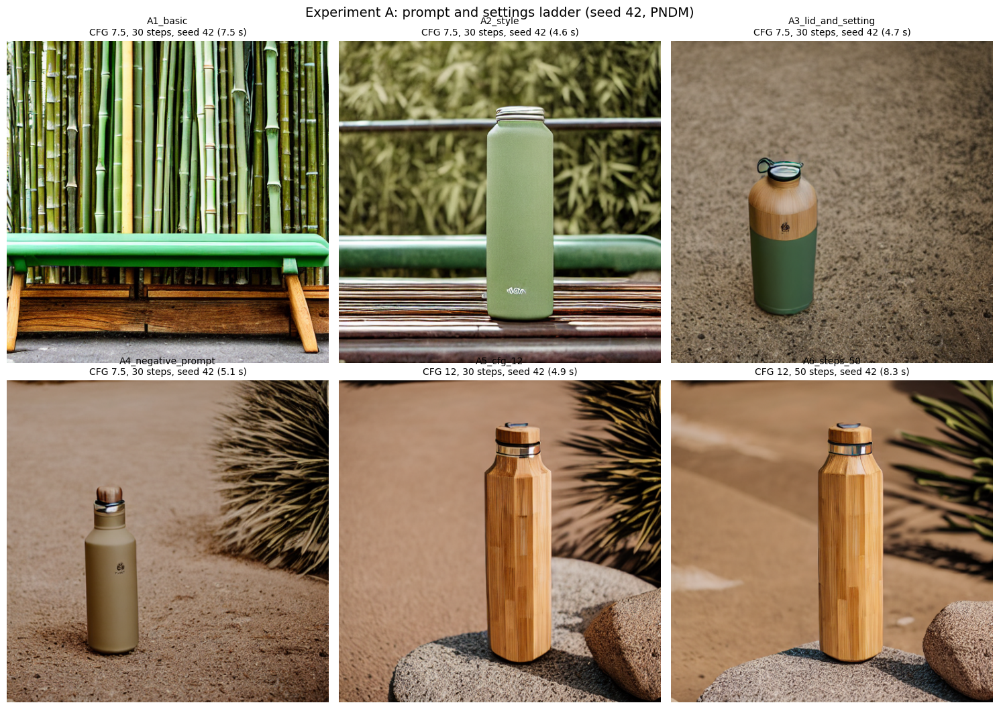

In [3]:
P_BASIC = "a sage green water bottle with a bamboo lid on a campus bench"
P_STYLE = P_BASIC + ", product photography, photorealistic, highly detailed, sharp focus, soft natural light"
P_FULL = ("a matte sage green stainless steel water bottle with a light brown wooden bamboo lid, "
          "standing on a stone bench, sunny desert university campus, sandstone buildings, palm trees, "
          "product photography, photorealistic, highly detailed, sharp focus")
NEGATIVE = ("metal lid, black lid, plastic lid, green lid, blurry, low quality, distorted, deformed, "
            "watermark, text, extra bottles, cluttered")

for name, text in [("P_BASIC", P_BASIC), ("P_STYLE", P_STYLE), ("P_FULL", P_FULL), ("NEGATIVE", NEGATIVE)]:
    print(f"{name}: {tokens(text)} tokens")

ladder = [
    generate("A1_basic", P_BASIC, group="A"),
    generate("A2_style", P_STYLE, group="A"),
    generate("A3_lid_and_setting", P_FULL, group="A"),
    generate("A4_negative_prompt", P_FULL, NEGATIVE, group="A"),
    generate("A5_cfg_12", P_FULL, NEGATIVE, cfg=12, group="A"),
    generate("A6_steps_50", P_FULL, NEGATIVE, cfg=12, steps=50, group="A"),
]
show(ladder, "Experiment A: prompt and settings ladder (seed 42, PNDM)")

## 7. Experiment B — Seed Consistency
The A4 configuration (full prompt, negative prompt, CFG 7.5, 30 steps) is repeated with four more seeds. A brand needs the product to look the same across images, so this tests how stable the design is when only the random starting noise changes.

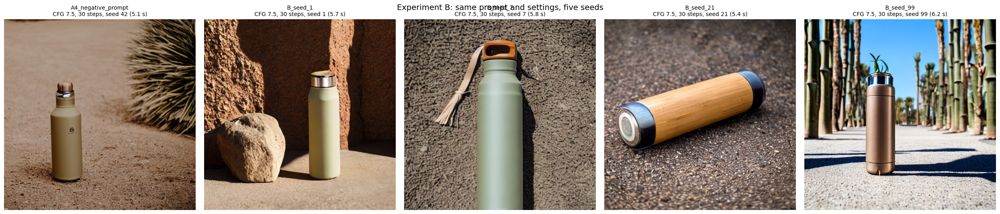

In [4]:
seed_runs = [ladder[3]] + [generate(f"B_seed_{s}", P_FULL, NEGATIVE, seed=s, group="B") for s in [1, 7, 21, 99]]
show(seed_runs, "Experiment B: same prompt and settings, five seeds", ncols=5)

## 8. Experiment C — Scheduler Comparison
The scheduler is the numerical method that reverses the diffusion process. Using the A4 prompt and seed, four schedulers from the lab's comparison table are tested, each at a typical step count for that method.

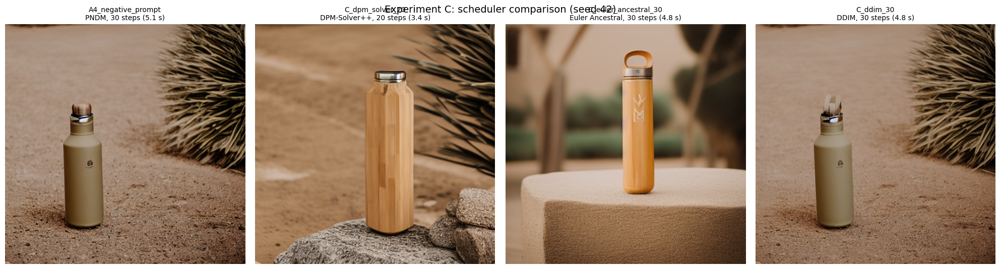

,label,scheduler,steps,seconds
0,A4_negative_prompt,PNDM,30,5.1
1,C_dpm_solver_20,DPM-Solver++,20,3.4
2,C_euler_ancestral_30,Euler Ancestral,30,4.8
3,C_ddim_30,DDIM,30,4.8


In [5]:
sched_runs = [
    ladder[3],
    generate("C_dpm_solver_20", P_FULL, NEGATIVE, steps=20, scheduler="DPM-Solver++", group="C"),
    generate("C_euler_ancestral_30", P_FULL, NEGATIVE, steps=30, scheduler="Euler Ancestral", group="C"),
    generate("C_ddim_30", P_FULL, NEGATIVE, steps=30, scheduler="DDIM", group="C"),
]
show(sched_runs, "Experiment C: scheduler comparison (seed 42)", ncols=4,
     caption_fn=lambda r: f"{r['scheduler']}, {r['steps']} steps")
display(pd.DataFrame([{k: r[k] for k in ["label", "scheduler", "steps", "seconds"]} for r in sched_runs]))

## 9. Experiment D — ControlNet Canny Conditioning
Text alone could not reliably produce a distinct lid in Week 1. ControlNet adds a second input: an edge map that fixes the **shape** of the output. A simple drawing of the TerraFlask silhouette is created in code, with a separate lid section and a visible seam. Canny edge detection turns it into the conditioning image, as in the lab. The prompt then controls materials, colour and setting.

Three runs are compared with the unconditioned A4 image:
- conditioning scale 0.6
- conditioning scale 1.0
- scale 1.0 with a different style prompt, to show that ControlNet keeps the structure while the text changes the look

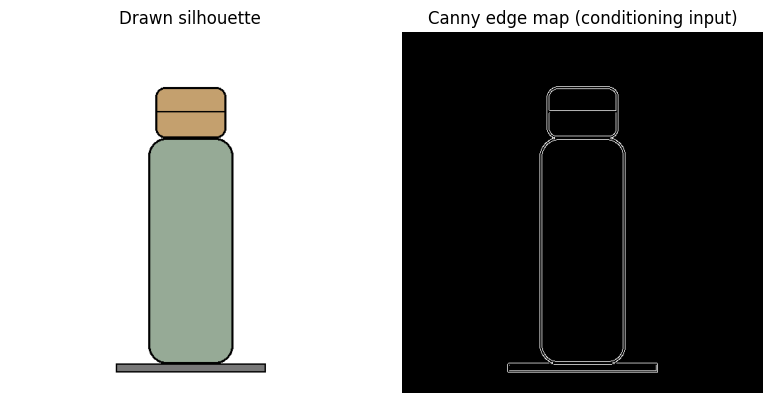

config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

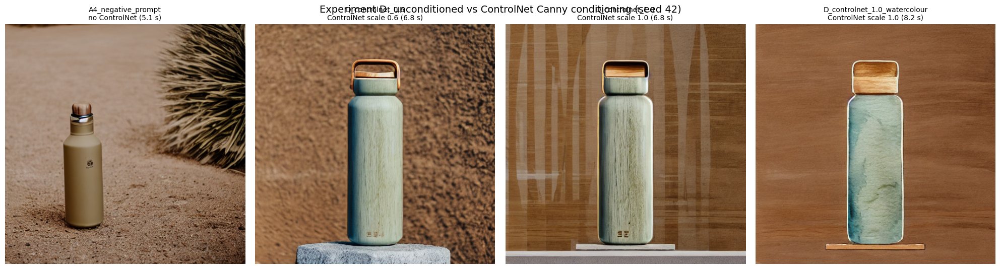

In [6]:
def draw_bottle_silhouette(size=512):
    img = Image.new("RGB", (size, size), "white")
    d = ImageDraw.Draw(img)
    d.rounded_rectangle([196, 150, 316, 470], radius=26, fill=(150, 170, 150), outline="black", width=3)  # body
    d.rounded_rectangle([206, 78, 306, 150], radius=14, fill=(196, 160, 110), outline="black", width=3)   # lid
    d.line([(206, 112), (306, 112)], fill="black", width=2)                                             # lid groove
    d.rectangle([150, 470, 362, 482], fill=(120, 120, 120), outline="black", width=2)                   # bench edge
    return img

sketch = draw_bottle_silhouette()
edges = cv2.Canny(np.array(sketch), 100, 200)
edge_map = Image.fromarray(np.stack([edges] * 3, axis=-1))
edge_map.save("outputs/D_canny_edge_map.png")

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(sketch); axes[0].set_title("Drawn silhouette")
axes[1].imshow(edge_map); axes[1].set_title("Canny edge map (conditioning input)")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

try:
    controlnet = ControlNetModel.from_pretrained("lllyasviel/sd-controlnet-canny", torch_dtype=torch.float16)
except Exception as err:
    print("Falling back to ControlNet v1.1 Canny:", err)
    controlnet = ControlNetModel.from_pretrained("lllyasviel/control_v11p_sd15_canny", torch_dtype=torch.float16)
cn_pipe = StableDiffusionControlNetPipeline(**pipe.components, controlnet=controlnet).to("cuda")
cn_pipe.set_progress_bar_config(disable=True)

P_WATERCOLOUR = ("a watercolour illustration of a sage green water bottle with a light brown wooden bamboo lid, "
                 "soft pastel desert background, artistic, hand painted")
cn_runs = [
    ladder[3],
    generate("D_controlnet_0.6", P_FULL, NEGATIVE, group="D", pipeline=cn_pipe, control_image=edge_map, control_scale=0.6),
    generate("D_controlnet_1.0", P_FULL, NEGATIVE, group="D", pipeline=cn_pipe, control_image=edge_map, control_scale=1.0),
    generate("D_controlnet_1.0_watercolour", P_WATERCOLOUR, NEGATIVE, group="D", pipeline=cn_pipe,
             control_image=edge_map, control_scale=1.0),
]
show(cn_runs, "Experiment D: unconditioned vs ControlNet Canny conditioning (seed 42)", ncols=4,
     caption_fn=lambda r: "no ControlNet" if r["controlnet_scale"] is None else f"ControlNet scale {r['controlnet_scale']}")

## 10. Images for the Captioning Evaluation
Lab Exercise 2 asks for five images from different domains. The product image is the A4 image. Three more scenes are generated with Stable Diffusion, and the diagram is a chart drawn with matplotlib, so it contains real, readable text.

| Domain | Image | What it tests |
|---|---|---|
| Product | A4 TerraFlask image | Attribute accuracy (colour, lid material) |
| Natural scene | Generated mountain lake | Easy, common subject |
| Social gathering | Generated student picnic | People and counting, where generated faces are often distorted |
| Abstract composition | Generated abstract artwork | No clear objects to name |
| Diagram | Matplotlib bar chart | Text, numbers and chart reading |

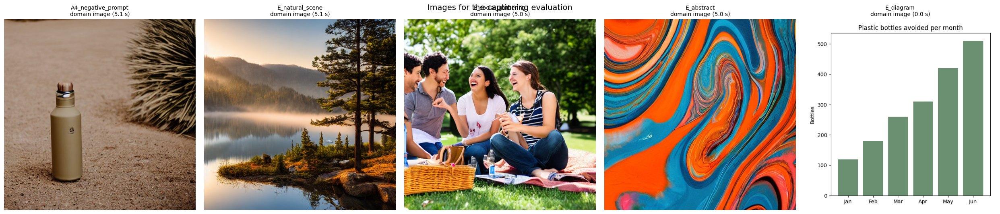

20 images generated and logged


In [7]:
scene_runs = [
    generate("E_natural_scene", "a calm mountain lake at sunrise, pine trees, mist over the water, photorealistic, highly detailed",
             "blurry, low quality", group="E"),
    generate("E_social_gathering", "a group of five university students having a picnic on a campus lawn, laughing, candid photo, natural light",
             "blurry, low quality, deformed", group="E"),
    generate("E_abstract", "abstract composition of swirling orange and teal paint, fluid art, high contrast",
             "text, watermark", group="E"),
]

fig, ax = plt.subplots(figsize=(5.12, 5.12), dpi=100)
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
values = [120, 180, 260, 310, 420, 510]
ax.bar(months, values, color="#6b8f71")
ax.set_title("Plastic bottles avoided per month")
ax.set_ylabel("Bottles")
plt.tight_layout()
plt.savefig("outputs/E_diagram.png", dpi=100)
plt.close(fig)
diagram = Image.open("outputs/E_diagram.png").convert("RGB").resize((512, 512))
records.append(dict(label="E_diagram", group="E", prompt="(matplotlib chart, not generated)", negative_prompt="",
                    guidance_scale=None, steps=None, seed=None, scheduler=None, controlnet_scale=None,
                    seconds=0.0, file="outputs/E_diagram.png", image=diagram))

caption_set = [ladder[3]] + scene_runs + [records[-1]]
show(caption_set, "Images for the captioning evaluation", ncols=5,
     caption_fn=lambda r: "domain image")

settings_log = pd.DataFrame([{k: v for k, v in r.items() if k != "image"} for r in records])
settings_log.to_csv("outputs/generation_settings.csv", index=False)
print(f"{len(records)} images generated and logged")

## 11. Image Captioning with BLIP-2
Stable Diffusion and ControlNet are unloaded to free GPU memory. BLIP-2 then connects a frozen image encoder to a frozen OPT-2.7B language model through a small trained Q-Former. It is loaded in float16 (about 7.5 GB of VRAM).

The demonstration function follows the lab's `caption_image()` design. It takes an image and a mode: free captioning, or a question in the `Question: … Answer:` format for visual question answering.

In [8]:
del cn_pipe, controlnet, pipe
gc.collect(); torch.cuda.empty_cache()

from transformers import Blip2Processor, Blip2ForConditionalGeneration
blip_processor = Blip2Processor.from_pretrained("Salesforce/blip2-opt-2.7b")
blip_model = Blip2ForConditionalGeneration.from_pretrained(
    "Salesforce/blip2-opt-2.7b", dtype=torch.float16, device_map="cuda")

def caption_image(image, mode="caption", max_new_tokens=40):
    prompt = None if mode == "caption" else f"Question: {mode} Answer:"
    inputs = blip_processor(images=image, text=prompt, return_tensors="pt").to("cuda")
    inputs["pixel_values"] = inputs["pixel_values"].to(torch.float16)
    with torch.no_grad():
        out = blip_model.generate(**inputs, max_new_tokens=max_new_tokens)
    text = blip_processor.batch_decode(out, skip_special_tokens=True)[0].strip()
    if prompt and text.startswith(prompt):
        text = text[len(prompt):].strip()
    return {"image_size": image.size, "mode": mode, "output_text": text}

print(caption_image(records[0]["image"]))

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.03k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/882 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.56M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

... (3 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/1247 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

{'image_size': (512, 512), 'mode': 'caption', 'output_text': 'a green bench sitting in front of a wall of bamboo'}


## 12. CLIP Alignment Scoring
CLIP gives a reference-free measure of how well a piece of text matches an image: the cosine similarity between their embeddings. Higher means closer. It is used three ways:
1. **Prompt–image similarity:** did the image follow the prompt?
2. **Caption–image similarity:** does the caption describe the image?
3. **Zero-shot attribute checks:** CLIP chooses the best description from a fixed list. This gives an automatic check of the two Week 1 failures, lid material and setting, across every TerraFlask image.

In [9]:
from transformers import CLIPModel, CLIPProcessor
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to("cuda").eval()
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

def clip_embed_text(texts):
    t = clip_processor.tokenizer(texts, padding=True, truncation=True, max_length=77, return_tensors="pt").to("cuda")
    with torch.no_grad():
        emb = clip_model.text_projection(clip_model.text_model(**t).pooler_output)
    return torch.nn.functional.normalize(emb, dim=-1)

def clip_embed_image(image):
    px = clip_processor.image_processor(images=image, return_tensors="pt")["pixel_values"].to("cuda")
    with torch.no_grad():
        emb = clip_model.visual_projection(clip_model.vision_model(pixel_values=px).pooler_output)
    return torch.nn.functional.normalize(emb, dim=-1)

def clip_similarity(image, text):
    return float(clip_embed_image(image) @ clip_embed_text([text]).T)

def clip_zero_shot(image, labels):
    probs = (100 * clip_embed_image(image) @ clip_embed_text(labels).T).softmax(dim=-1)[0]
    return dict(zip(labels, probs.tolist()))

LID_LABELS = ["a water bottle with a wooden bamboo lid", "a water bottle with a metal lid",
              "a water bottle with a black plastic lid", "a water bottle with a green lid"]
SETTING_LABELS = ["a desert campus with sandstone buildings and palm trees", "a green park with lush trees",
                  "a plain studio background"]
print("CLIP ready:", clip_similarity(records[0]["image"], "a water bottle"))

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP ready: 0.173740416765213


## 13. Evaluation of the TerraFlask Images
For every TerraFlask image, the table records:
- the prompt–image CLIP similarity;
- CLIP's zero-shot verdict on the lid and the setting;
- BLIP-2's caption and the caption–image similarity;
- BLIP-2's answer to "What is the lid made of?".

The caption–prompt similarity measures the lab's closed loop: prompt → image → caption, compared back to the prompt.

In [10]:
product_recs = [r for r in records if r["group"] in {"A", "B", "C", "D"}]
rows = []
for r in product_recs:
    img = r["image"]
    lid = clip_zero_shot(img, LID_LABELS)
    setting = clip_zero_shot(img, SETTING_LABELS)
    cap = caption_image(img)["output_text"]
    rows.append({
        "label": r["label"],
        "prompt_sim": clip_similarity(img, r["prompt"]),
        "lid_verdict": max(lid, key=lid.get).replace("a water bottle with ", ""),
        "p_bamboo_lid": lid[LID_LABELS[0]],
        "setting_verdict": max(setting, key=setting.get),
        "caption": cap,
        "caption_sim": clip_similarity(img, cap),
        "caption_prompt_sim": float(clip_embed_text([cap]) @ clip_embed_text([r["prompt"]]).T),
        "vqa_lid": caption_image(img, "What is the lid of the bottle made of?")["output_text"],
    })
product_eval = pd.DataFrame(rows)
product_eval.to_csv("outputs/product_image_evaluation.csv", index=False)
display(product_eval.round(3))

print("Group means:")
display(product_eval.assign(group=product_eval.label.str[0]).groupby("group")[
    ["prompt_sim", "p_bamboo_lid", "caption_sim", "caption_prompt_sim"]].mean().round(3))

,label,prompt_sim,lid_verdict,p_bamboo_lid,setting_verdict,caption,caption_sim,caption_prompt_sim,vqa_lid
0,A1_basic,0.299,a wooden bamboo lid,0.999,a plain studio background,a green bench sitting in front of a wall of bamboo,0.372,0.695,bamboo
1,A2_style,0.381,a green lid,0.397,a plain studio background,a green water bottle sitting on a bench,0.340,0.680,"It's made of a durable, lightweight, and durable material"
2,A3_lid_and_setting,0.327,a wooden bamboo lid,0.913,a plain studio background,a green and brown water bottle sitting on the ground,0.326,0.487,bamboo
3,A4_negative_prompt,0.343,a metal lid,0.315,a plain studio background,a tan water bottle sitting on the ground,0.300,0.464,"It's made of a high-density polyethylene (HDPE) material that is resistant to heat, cold, and chemicals"
4,A5_cfg_12,0.417,a wooden bamboo lid,1.000,a plain studio background,a wooden water bottle sitting on a rock,0.333,0.461,bamboo
5,A6_steps_50,0.410,a wooden bamboo lid,1.000,a plain studio background,a bamboo water bottle sitting on a rock,0.343,0.513,bamboo
6,B_seed_1,0.377,a metal lid,0.377,a plain studio background,a green water bottle next to a rock,0.312,0.416,It's made of a special type of plastic called polypropylene
7,B_seed_7,0.352,a wooden bamboo lid,0.489,a plain studio background,a green water bottle with a brown handle,0.345,0.452,"It's made of a durable, lightweight, and durable plastic"
8,B_seed_21,0.288,a wooden bamboo lid,0.999,a plain studio background,a bamboo battery sitting on the ground,0.326,0.386,bamboo
9,B_seed_99,0.405,a wooden bamboo lid,0.700,a plain studio background,a plant in a brown container sitting on a sidewalk,0.250,0.386,Plastic


Group means:


,prompt_sim,p_bamboo_lid,caption_sim,caption_prompt_sim
group,,,,
A,0.363,0.771,0.336,0.550
B,0.355,0.641,0.308,0.410
C,0.366,0.731,0.313,0.487
D,0.328,0.946,0.310,0.459


## 14. Multi-Image Captioning Pipeline (Lab Exercise 2)
The five domain images are captioned and asked the same three questions. Captions are ranked by their CLIP alignment with the image.

In [11]:
QUESTIONS = ["What is the main colour in the image?", "How many people are in the image?",
             "What emotion does this image evoke?"]
rows = []
for r in caption_set:
    cap = caption_image(r["image"])["output_text"]
    row = {"image": r["label"], "caption": cap, "caption_sim": clip_similarity(r["image"], cap)}
    for q in QUESTIONS:
        row[q] = caption_image(r["image"], q)["output_text"]
    rows.append(row)
domain_eval = pd.DataFrame(rows).sort_values("caption_sim", ascending=False)
domain_eval.to_csv("outputs/domain_caption_evaluation.csv", index=False)
display(domain_eval.round(3))

print("Detailed descriptions:")
for r in caption_set:
    print(f"- {r['label']}: {caption_image(r['image'], 'Describe this image in detail.', max_new_tokens=60)['output_text']}")

,image,caption,caption_sim,What is the main colour in the image?,How many people are in the image?,What emotion does this image evoke?
4,E_diagram,a bar chart showing the number of plastic bottles that were avoided per month,0.394,blue,"1,000,000",happiness
3,E_abstract,"an abstract painting with orange, blue and black swirled paint",0.357,Orange,None.,Fear
1,E_natural_scene,a lake surrounded by trees and mountains at sunrise,0.331,The main colour is the blue sky,None,happiness
2,E_social_gathering,group of friends having picnic in the park,0.331,Green,4,happiness
0,A4_negative_prompt,a tan water bottle sitting on the ground,0.300,Desert,1,happiness


Detailed descriptions:
- A4_negative_prompt: 
- E_natural_scene: The sun rises over a lake in the mountains at sunrise
- E_social_gathering: A group of friends having a picnic in the park
- E_abstract: This image is a painting of a blue, orange, and red swirl
- E_diagram: the bar graph shows the number of plastic bottles avoided per month


## 15. Analysis

### 15.1 Experiment A: prompt and settings ladder

| Step | What changed | Result |
|---|---|---|
| A1 | Basic prompt | **No bottle at all.** A green bench in front of a bamboo grove. "Sage green" went to the bench and "bamboo" became the background |
| A2 | + Style and quality | A sage-green bottle appears, but with a steel cap; bamboo is still the background |
| A3 | + Explicit lid and desert setting | Bamboo moves onto the bottle, but onto the **upper half of the body**, not the lid; a clear loop-top lid; sandy ground |
| A4 | + Negative prompt | A small wooden-looking cap on a steel neck, the closest result to the brief, but the body drifts from sage to **tan**; desert path with spiky desert plants |
| A5 | CFG 7.5 → 12 | The **whole bottle** becomes bamboo wood; the sage colour disappears; rock, sand and palm fronds |
| A6 | Steps 30 → 50 | Almost identical to A5, with slightly finer texture, at 70% more generation time (8.3 s vs 4.9 s) |

**The setting failure was fixed by prompt design.** Once the prompt named a desert campus (A3 onwards), every image moved from Week 1's green European park to sand, rock and desert plants. The sandstone buildings and campus never appeared, however: the model rendered the parts of the setting with strong visual identity (sand, palms) and dropped the abstract part ("university campus").

**The lid failure was not fixed by prompt design.** The word "bamboo" was always rendered, but almost never on the lid: on the background (A1, A2), the body (A3), then the entire bottle (A5, A6). This is the attribute-binding weakness identified in Week 1, seen more clearly. The CLIP text encoder tells the model *that* bamboo is in the scene, not *which object* it belongs to. Higher guidance made this worse: CFG 12 pushed the strongest concept, wood, across the whole product. The negative prompt helped most, giving the only correct lid in the ladder (A4), but it also shifted the body colour towards the desert palette around it.

### 15.2 Experiment B: seed consistency
Five seeds with identical settings produced **five different product designs**:
- a tan bottle with a small wooden cap (42);
- a pale sage bottle with a steel cap against red sandstone (1);
- a sage bottle with a wooden carry-loop lid (7);
- a bamboo tumbler lying on its side (21);
- a bronze bottle with a plant growing out of its top, in an avenue of palms (99).

Only seed 7 matched both the sage body and the wooden lid. A brand needs the same product in every image, and text-to-image generation alone cannot provide that: the seed decides the design as much as the prompt does.

### 15.3 Experiment C: schedulers

| Scheduler | Steps | Time | Result with the same seed |
|---|---|---|---|
| PNDM (default) | 30 | 5.1 s | Tan bottle, small wooden cap |
| DPM-Solver++ | 20 | **3.4 s** | Bamboo-body bottle, steel cap, on a rock |
| Euler Ancestral | 30 | 4.8 s | Bamboo-body bottle with a wooden loop lid on a sandstone plinth |
| DDIM | 30 | 4.8 s | Near-identical composition to PNDM, with a loop-style lid |

DPM-Solver++ was the fastest, about a third quicker than PNDM, because it needs fewer steps, with no visible loss of quality. PNDM and DDIM are deterministic methods and converged on almost the same image. DPM-Solver++ and Euler Ancestral took different denoising paths and produced different products. The scheduler is therefore a creative variable, not just a speed setting: changing it after choosing an image changes the image.

### 15.4 Experiment D: ControlNet
ControlNet Canny conditioning fixed the problem that prompting could not. In all three conditioned images the bottle follows the drawn silhouette: a tall rounded body with a **separate, light-wood lid in the right place**. The body colour also returned to a pale sage-grey instead of A4's tan. With the same edge map and a watercolour prompt, the structure was kept while the style changed completely, confirming that ControlNet separates *shape* (from the edge map) from *appearance* (from the text). CLIP's zero-shot check rated the lid as bamboo with probability 0.85, 0.99 and 1.00, and group D had the highest mean bamboo-lid probability (0.95).

The trade-off is control versus freedom. The product's design now has to be drawn by a person, and the backgrounds became plainer, since the edge map leaves the model less room to compose a scene. For product imagery, where the product must look like the real one, that trade is worthwhile.

### 15.5 Caption accuracy
Every caption was compared with its image by eye:
- **TerraFlask images (16):** 12 accurate, 1 partly accurate, 3 wrong.
- **Domain images (5):** all 5 captions accurate.

Accurate captions picked out the main object and its dominant colour or material well: "a tan water bottle sitting on the ground" (A4), "a wooden water bottle sitting on a rock" (A5), "a green water bottle with a brown handle" (seed 7). The failures show three limitations:
- **Wrong object on unusual images.** The bamboo tumbler lying on its side (seed 21) became "a bamboo battery". The bottle with a plant on top (seed 99) became "a plant in a brown container".
- **Attribute binding errors, the same weakness as Stable Diffusion.** The ControlNet 1.0 image, a sage bottle with a wooden lid, was captioned "a wooden water bottle with a green lid": the right attributes on the wrong parts.
- **Invented details.** The watercolour bottle was described as containing "green liquid", which is not shown.

Captions were also **incomplete as alt text.** They rarely mentioned the setting ("sitting on the ground") and never the lid unless it dominated the image.

**Visual question answering was much less reliable than captioning:**
- **Presupposition.** Asked what the lid was made of, BLIP-2 answered "bamboo" for A1, an image containing no bottle. A question that assumes something exists gets an answer that assumes it too.
- **Answering from the whole image.** For bottles with bamboo bodies and steel caps (A5, A6), it answered "bamboo" for the lid. When unsure, it fell back on invented specifics: "high-density polyethylene (HDPE)", "polypropylene".
- **Counting.** It correctly counted 4 people at the picnic. Notably, Stable Diffusion generated four people although the prompt asked for five, a counting failure on the generation side. It also said "1" person for the product image, which has none, and "1,000,000" people for the bar chart.
- **Colour and emotion.** The chart's green bars were called "blue". "Happiness" was the answer for 4 of 5 images, including a water bottle on sand: a default answer, not a judgement.
- **Empty output.** The detailed-description prompt returned nothing for the product image.

The bar chart produced the best caption of all, "a bar chart showing the number of plastic bottles that were avoided per month", which correctly reads the chart's title. Captioning is strongest when the image contains readable text and a conventional layout.

### 15.6 Reliability of the automated metrics
The automated checks failed in instructive ways, so none can be used without human review:
- **CLIP zero-shot lid check.** It rated A1, which has no bottle, as having a bamboo lid with probability 0.999, because of the bamboo background. It rated the all-bamboo bottles in A5 and A6 the same. Like Stable Diffusion, CLIP detects whether a concept is present, not where it is.
- **CLIP zero-shot setting check.** It chose "a plain studio background" for all 16 product images, including clear desert scenes. The label set was poorly designed: the generated close-ups with blurred backgrounds matched none of the specific scene descriptions, so the most generic label won every time.
- **Prompt–image similarity** was highest for A5 and A6 (0.42, 0.41), which ignore the sage colour entirely, and lowest on average for group D (0.33), which matched the brief best. CLIP similarity rewards images that contain many prompt concepts, not images where each concept is in the right place.
- **Caption–prompt similarity (the closed loop)** was highest for A1 (0.70), whose caption shares the words "green", "bench" and "bamboo" with the prompt although no bottle was generated.

### 15.7 Responsible-use observations
- **Context bias.** Without explicit instruction, Stable Diffusion defaulted to Western scenery (Week 1). It could be steered towards a hot-climate setting, but not to a specific campus, so generated marketing imagery for non-Western audiences needs a deliberate check.
- **Disclosure.** All images are synthetic and look photographic. Under the EU AI Act's transparency rules, published synthetic images should be labelled as AI-generated, and a generated product image that does not match the real product would also be misleading advertising.
- **Licences.** Stable Diffusion v1.5 is released under CreativeML OpenRAIL-M, which permits commercial use with usage restrictions. BLIP-2 and CLIP are MIT-licensed. Training-data copyright for Stable Diffusion (LAION-5B) remains legally unsettled.

## 16. Conclusions
**Image generation.** Prompt design fixed one of the two failures found in Week 1: naming a desert setting moved every scene from a European park to sand, rock and desert plants. It could not fix the other. The bamboo lid was rendered on the background, the body or the whole bottle, but almost never on the lid, because Stable Diffusion v1.5's text encoder does not bind attributes to objects. Among the settings:
- the **negative prompt** gave the largest single improvement;
- **higher guidance** exaggerated the dominant concept;
- **more steps** added little beyond time;
- the **seed and scheduler** changed the product design as much as the prompt did.

**Structural conditioning with ControlNet was the only method that reliably produced the specified product**: a sage bottle with a wooden lid in all three conditioned images, kept even when the style changed to watercolour. For brand or product imagery, the practical workflow is a reference drawing or photo with ControlNet, a fast scheduler (DPM-Solver++, 20 steps), a negative prompt and moderate guidance, with the product's shape supplied rather than described.

**Image captioning.** BLIP-2 produced short, mostly accurate captions: 17 of 21 accurate and 1 partly accurate. It is strongest on conventional scenes and charts with readable titles. It is not yet reliable enough to generate product alt text unsupervised: it misidentified unusual objects, swapped attributes between parts, invented details, and its question answering accepted false premises and defaulted to stock answers. A realistic use is a **first draft of alt text that a person checks**, combined with product data (name, colour, material) taken from the catalogue rather than from the image.

**Evaluation.** The most important lesson is that the automatic metrics shared the generator's own blind spot. CLIP, the same family of model as Stable Diffusion's text encoder, could not tell a bamboo lid from a bamboo background or a bamboo body. It ranked the images that best matched the brief lowest on prompt similarity. Every automated score in this notebook needed human review to be interpreted correctly. A production pipeline would need part-level checks (object detection on the lid region) or human approval before any generated image is published.